# Effect of Replacing One Best-Response Agent with a Threshold-Link Agent

This notebook analyzes the existing paired simulation run. For every network size and parameter row, it compares an all-best-response population with the same population after replacing one best-response agent with one threshold-link agent. All time comparisons use activation opportunities per agent.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import zarr
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RUN = ROOT / "artifacts/simulation_runs/run-20260715T172106.zarr"

WITHOUT_THRESHOLD = 0
WITH_THRESHOLD = 1
PRACTICAL_EFFECT = 0.05
SIZE_COLORS = {10: "#3d405b", 50: "#e07a5f", 100: "#2a9d8f"}

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 20)

## 1. Experimental Design

The continuous behavioral parameters are a shared scrambled Sobol design. Visibility is sampled from the six supported integer values. The simulator seed is also shared, so each treatment row has an exact baseline counterpart.

In [2]:
root = zarr.open_group(RUN, mode="r")
if root.attrs["has_failures"]:
    raise ValueError("The source run contains failed rows")

parameters = np.asarray(root["metadata/parameters"], dtype=np.float32)
parameter_names = list(root.attrs["parameter_names"])
n_agents = np.asarray(root["metadata/n_agents"], dtype=int)
input_coordinates = np.asarray(root["metadata/input_coordinates"], dtype=int)
result_input_index = np.asarray(root["results/input_index"], dtype=int)
n_parameter_rows = parameters.shape[2]
n_compositions = parameters.shape[1]

sampled_names = [
    "visibility_distance",
    "threshold_link.link_threshold",
    "best_response.outside_optimism",
    "best_response.exploration",
]
sampled_columns = [parameter_names.index(name) for name in sampled_names]
paired_parameters = parameters[:, :, :, sampled_columns]
if not np.array_equal(paired_parameters[:, 0], paired_parameters[:, 1]):
    raise ValueError("Treatment and baseline parameter rows do not match")

def extract_normalized_output(
    output_name: str, normalized_times: np.ndarray
) -> np.ndarray:
    """Read selected normalized times without retaining full raw trajectories."""
    output = root[f"results/outputs/{output_name}"]
    tail_shape = output.shape[2:]
    values = np.full(
        (
            len(n_agents),
            n_compositions,
            n_parameter_rows,
            len(normalized_times),
            *tail_shape,
        ),
        np.nan,
        dtype=np.float32,
    )

    chunk_rows = output.chunks[0]
    for start in range(0, output.shape[0], chunk_rows):
        stop = min(start + chunk_rows, output.shape[0])
        coordinates = input_coordinates[result_input_index[start:stop]]
        block = np.asarray(output[start:stop])
        steps = np.rint(
            n_agents[coordinates[:, 0], None] * normalized_times[None, :]
        ).astype(int)
        row_index = np.arange(stop - start)[:, None]
        selected = (
            block[row_index, steps]
            if block.ndim == 2
            else block[row_index, steps, :]
        )
        values[
            coordinates[:, 0], coordinates[:, 1], coordinates[:, 2]
        ] = selected

    return values

design_summary = pd.DataFrame(
    {
        "Design item": [
            "Network sizes",
            "Population compositions",
            "Shared parameter rows",
            "Episodes per configuration",
            "Raw activation steps",
            "Common normalized horizon",
            "Stored trajectories",
        ],
        "Value": [
            ", ".join(map(str, n_agents)),
            "all best-response; one threshold-link replacement",
            f"{n_parameter_rows:,}",
            root.attrs["policy_config"]["simulator"]["n_episodes"],
            root.attrs["policy_config"]["simulator"]["max_steps"],
            "40 activation opportunities per agent",
            "welfare, indegree, centralization, policy payoff",
        ],
    }
)
design_summary

,Design item,Value
0,Network sizes,"10, 50, 100"
1,Population compositions,all best-response; one threshold-link replacement
2,Shared parameter rows,"16,384"
3,Episodes per configuration,16
4,Raw activation steps,4000
5,Common normalized horizon,40 activation opportunities per agent
6,Stored trajectories,"welfare, indegree, centralization, policy payoff"


## 2. Paired Welfare Effects

For size $n$, parameter row $j$, and normalized time $t$, the replacement effect is

$$
\Delta W_{nj}(t)=W_{n,\text{one threshold},j}(t)-W_{n,\text{all BR},j}(t).
$$

The 5–95% ranges below describe heterogeneity across the sampled parameter space; they are not confidence intervals.

In [3]:
normalized_time = np.linspace(0.0, 40.0, 401)
welfare = extract_normalized_output(
    "centered_mean_welfare.mean", normalized_time
)
welfare_delta = welfare[:, WITH_THRESHOLD] - welfare[:, WITHOUT_THRESHOLD]
baseline_welfare = welfare[:, WITHOUT_THRESHOLD, :, -1].copy()
threshold_welfare = welfare[:, WITH_THRESHOLD, :, -1].copy()
del welfare

column = {name: parameter_names.index(name) for name in parameter_names}
theta = pd.DataFrame(
    {
        "parameter_row": np.arange(n_parameter_rows),
        "visibility": parameters[0, 0, :, column["visibility_distance"]].astype(int),
        "link_threshold": parameters[
            0, 0, :, column["threshold_link.link_threshold"]
        ],
        "outside_optimism": parameters[
            0, 0, :, column["best_response.outside_optimism"]
        ],
        "exploration": parameters[
            0, 0, :, column["best_response.exploration"]
        ],
    }
)

effect_frames = []
for size_index, size in enumerate(n_agents):
    frame = theta.copy()
    frame["n_agents"] = size
    frame["d_welfare"] = welfare_delta[size_index, :, -1]
    effect_frames.append(frame)
effects = pd.concat(effect_frames, ignore_index=True)

In [4]:
time_average_effect = np.trapezoid(
    welfare_delta, normalized_time, axis=-1
) / normalized_time[-1]

summary_rows = []
for size_index, size in enumerate(n_agents):
    delta = welfare_delta[size_index, :, -1]
    q05, median, q95 = np.quantile(delta, [0.05, 0.50, 0.95])
    visibility_stratified = np.mean(
        [delta[theta.visibility == value].mean() for value in range(1, 7)]
    )
    summary_rows.append(
        {
            "n_agents": size,
            "All-BR welfare": baseline_welfare[size_index].mean(),
            "One-threshold welfare": threshold_welfare[size_index].mean(),
            "Mean effect": delta.mean(),
            "Visibility-stratified mean": visibility_stratified,
            "Median effect": median,
            "5%-95% parameter range": f"[{q05:.4f}, {q95:.4f}]",
            "P(effect > 0)": np.mean(delta > 0),
            f"P(effect > {PRACTICAL_EFFECT:g})": np.mean(
                delta > PRACTICAL_EFFECT
            ),
            f"P(effect < -{PRACTICAL_EFFECT:g})": np.mean(
                delta < -PRACTICAL_EFFECT
            ),
            "Time-average effect": time_average_effect[size_index].mean(),
        }
    )

welfare_summary = pd.DataFrame(summary_rows).set_index("n_agents")
welfare_summary.style.format(
    {
        "All-BR welfare": "{:.4f}",
        "One-threshold welfare": "{:.4f}",
        "Mean effect": "{:.4f}",
        "Visibility-stratified mean": "{:.4f}",
        "Median effect": "{:.4f}",
        "P(effect > 0)": "{:.1%}",
        f"P(effect > {PRACTICAL_EFFECT:g})": "{:.1%}",
        f"P(effect < -{PRACTICAL_EFFECT:g})": "{:.1%}",
        "Time-average effect": "{:.4f}",
    }
)

,All-BR welfare,One-threshold welfare,Mean effect,Visibility-stratified mean,Median effect,5%-95% parameter range,P(effect > 0),P(effect > 0.05),P(effect < -0.05),Time-average effect
n_agents,,,,,,,,,,
10,0.6590,0.5715,-0.0875,-0.0876,-0.0760,"[-0.2354, 0.0208]",13.0%,1.3%,59.5%,-0.0483
50,0.2461,0.4538,0.2076,0.2082,0.0778,"[-0.0530, 0.8039]",72.8%,52.9%,5.4%,0.1367
100,-0.0677,0.1917,0.2593,0.2600,0.1028,"[-0.0338, 1.0419]",82.0%,68.3%,4.0%,0.1304


## 3. Effect Dynamics

The endpoint does not describe when an effect appears or whether it reverses. The solid line is the mean paired effect, the dashed line is the median, and the band is the 5–95% parameter-row range.

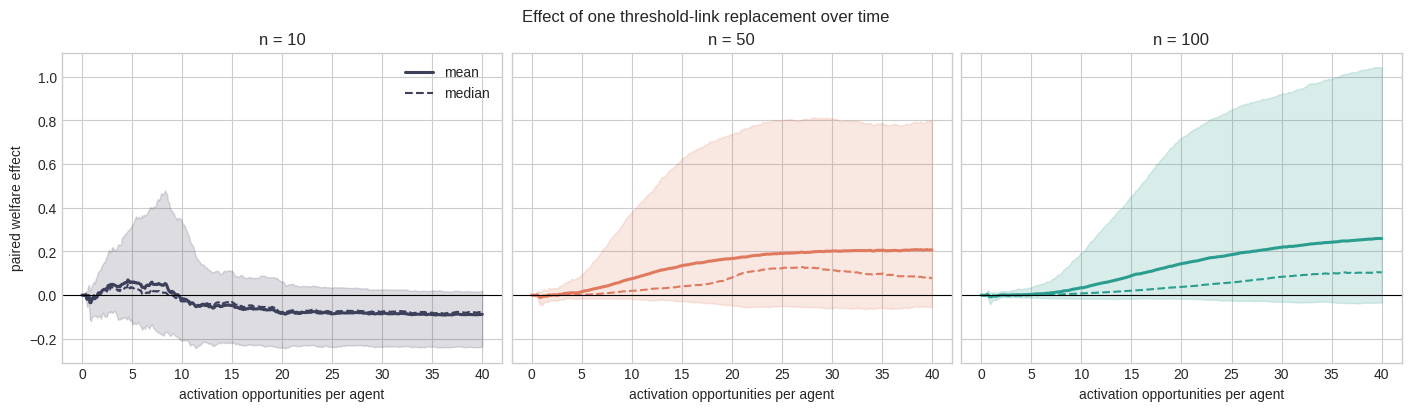

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True, constrained_layout=True)
for size_index, (size, ax) in enumerate(zip(n_agents, axes, strict=True)):
    delta = welfare_delta[size_index]
    q05, median, q95 = np.quantile(delta, [0.05, 0.50, 0.95], axis=0)
    mean = delta.mean(axis=0)
    color = SIZE_COLORS[size]
    ax.fill_between(normalized_time, q05, q95, color=color, alpha=0.18)
    ax.plot(normalized_time, mean, color=color, lw=2.2, label="mean")
    ax.plot(normalized_time, median, color=color, lw=1.5, ls="--", label="median")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"n = {size}")
    ax.set_xlabel("activation opportunities per agent")
axes[0].set_ylabel("paired welfare effect")
axes[0].legend(frameon=False)
fig.suptitle("Effect of one threshold-link replacement over time")
plt.show()

In [6]:
dynamic_rows = []
for size_index, size in enumerate(n_agents):
    delta = welfare_delta[size_index]
    mean_curve = delta.mean(axis=0)
    row_average = time_average_effect[size_index]
    peak_index = int(np.argmax(mean_curve))
    trough_index = int(np.argmin(mean_curve))
    dynamic_rows.append(
        {
            "n_agents": size,
            "Time-average effect": row_average.mean(),
            "Median time-average effect": np.median(row_average),
            "P(time-average effect > 0)": np.mean(row_average > 0),
            "Peak time": normalized_time[peak_index],
            "Peak effect": mean_curve[peak_index],
            "Trough time": normalized_time[trough_index],
            "Trough effect": mean_curve[trough_index],
            "Endpoint effect": mean_curve[-1],
        }
    )

dynamic_summary = pd.DataFrame(dynamic_rows).set_index("n_agents")
dynamic_summary.style.format(
    {
        "Time-average effect": "{:.4f}",
        "Median time-average effect": "{:.4f}",
        "P(time-average effect > 0)": "{:.1%}",
        "Peak time": "{:.1f}",
        "Peak effect": "{:.4f}",
        "Trough time": "{:.1f}",
        "Trough effect": "{:.4f}",
        "Endpoint effect": "{:.4f}",
    }
)

,Time-average effect,Median time-average effect,P(time-average effect > 0),Peak time,Peak effect,Trough time,Trough effect,Endpoint effect
n_agents,,,,,,,,
10,-0.0483,-0.0451,22.6%,4.6,0.0702,36.2,-0.0913,-0.0875
50,0.1367,0.0857,78.3%,38.5,0.2086,0.8,-0.0100,0.2076
100,0.1304,0.0491,82.6%,39.8,0.2597,1.0,-0.0075,0.2593


## 4. Parameter-Space Heterogeneity

`link_threshold` is a proportion of locally possible outgoing links, not an action probability (`p_act` is fixed at one). Its interpretation therefore depends directly on visibility. The following figures use empirical conditional means rather than a linear threshold slope.

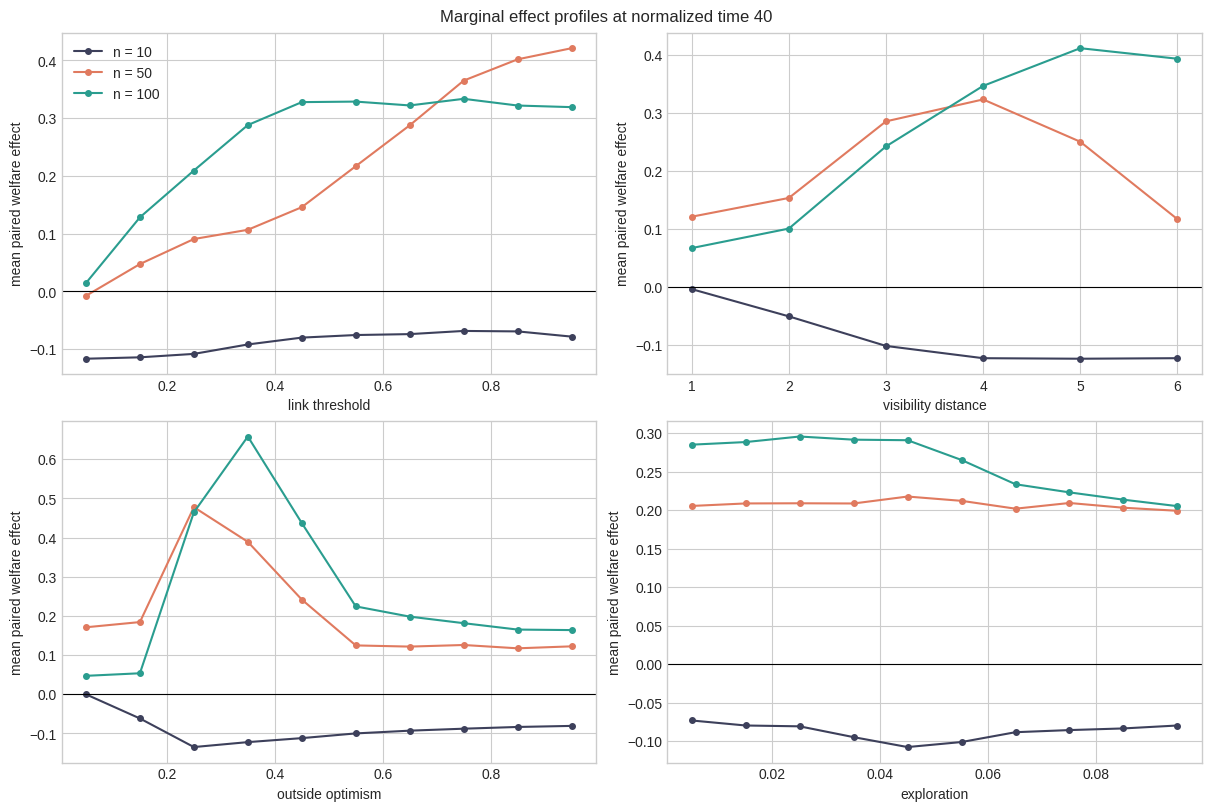

In [7]:
profile_specs = {
    "link_threshold": (np.linspace(0, 1, 11), "link threshold"),
    "visibility": (np.arange(0.5, 7.5, 1), "visibility distance"),
    "outside_optimism": (np.linspace(0, 1, 11), "outside optimism"),
    "exploration": (np.linspace(0.0001, 0.1, 11), "exploration"),
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for (feature, (edges, label)), ax in zip(profile_specs.items(), axes.flat, strict=True):
    for size in n_agents:
        selected = effects.loc[effects.n_agents == size].copy()
        selected["bin"] = pd.cut(selected[feature], edges, include_lowest=True)
        profile = selected.groupby("bin", observed=True).agg(
            x=(feature, "mean"),
            mean_effect=("d_welfare", "mean"),
        )
        ax.plot(
            profile.x,
            profile.mean_effect,
            marker="o",
            ms=4,
            color=SIZE_COLORS[size],
            label=f"n = {size}",
        )
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xlabel(label)
    ax.set_ylabel("mean paired welfare effect")
axes[0, 0].legend(frameon=False)
fig.suptitle("Marginal effect profiles at normalized time 40")
plt.show()

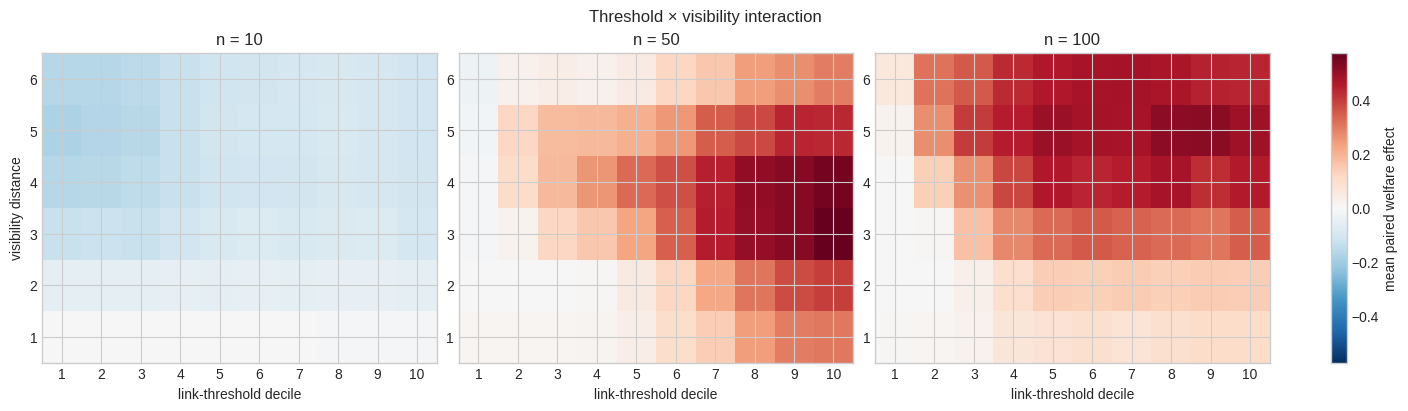

In [8]:
threshold_edges = np.linspace(0, 1, 11)
visibility_edges = np.arange(0.5, 7.5, 1)
threshold_visibility_grids = []
for size in n_agents:
    selected = effects.loc[effects.n_agents == size].copy()
    selected["threshold_bin"] = pd.cut(
        selected.link_threshold, threshold_edges, labels=False, include_lowest=True
    )
    selected["visibility_bin"] = pd.cut(
        selected.visibility, visibility_edges, labels=False, include_lowest=True
    )
    grid = selected.pivot_table(
        index="visibility_bin",
        columns="threshold_bin",
        values="d_welfare",
        aggfunc="mean",
        observed=True,
    ).reindex(index=range(6), columns=range(10))
    threshold_visibility_grids.append(grid.to_numpy())

color_limit = max(np.nanmax(np.abs(grid)) for grid in threshold_visibility_grids)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for size, grid, ax in zip(n_agents, threshold_visibility_grids, axes, strict=True):
    image = ax.imshow(
        grid, origin="lower", aspect="auto", cmap="RdBu_r",
        vmin=-color_limit, vmax=color_limit,
    )
    ax.set_title(f"n = {size}")
    ax.set_xlabel("link-threshold decile")
    ax.set_xticks(range(10), range(1, 11))
    ax.set_yticks(range(6), range(1, 7))
axes[0].set_ylabel("visibility distance")
fig.colorbar(image, ax=axes, label="mean paired welfare effect")
fig.suptitle("Threshold × visibility interaction")
plt.show()

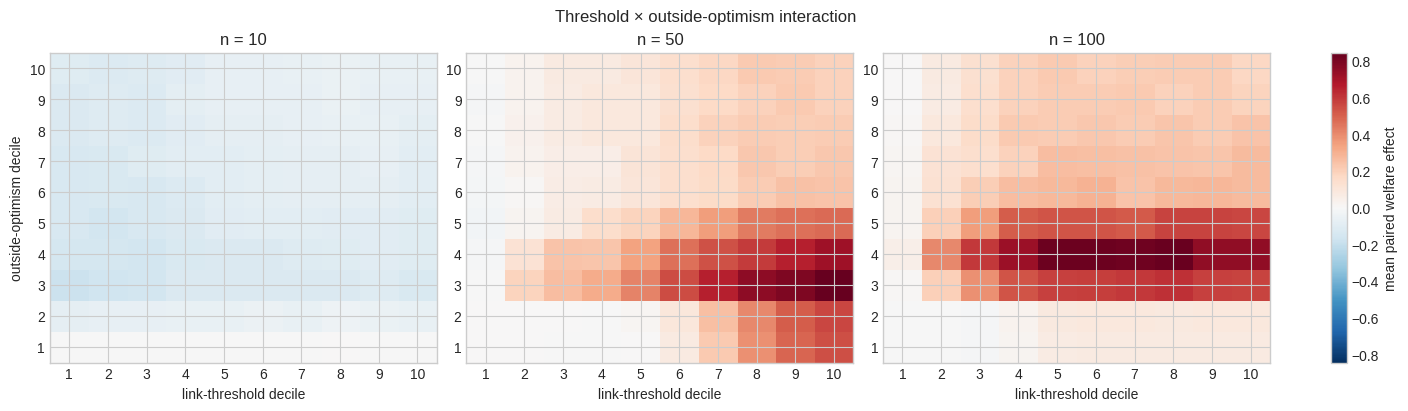

In [9]:
optimism_edges = np.linspace(0, 1, 11)
threshold_optimism_grids = []
for size in n_agents:
    selected = effects.loc[effects.n_agents == size].copy()
    selected["threshold_bin"] = pd.cut(
        selected.link_threshold, threshold_edges, labels=False, include_lowest=True
    )
    selected["optimism_bin"] = pd.cut(
        selected.outside_optimism, optimism_edges, labels=False, include_lowest=True
    )
    grid = selected.pivot_table(
        index="optimism_bin",
        columns="threshold_bin",
        values="d_welfare",
        aggfunc="mean",
        observed=True,
    ).reindex(index=range(10), columns=range(10))
    threshold_optimism_grids.append(grid.to_numpy())

color_limit = max(np.nanmax(np.abs(grid)) for grid in threshold_optimism_grids)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for size, grid, ax in zip(n_agents, threshold_optimism_grids, axes, strict=True):
    image = ax.imshow(
        grid, origin="lower", aspect="auto", cmap="RdBu_r",
        vmin=-color_limit, vmax=color_limit,
    )
    ax.set_title(f"n = {size}")
    ax.set_xlabel("link-threshold decile")
    ax.set_xticks(range(10), range(1, 11))
    ax.set_yticks(range(10), range(1, 11))
axes[0].set_ylabel("outside-optimism decile")
fig.colorbar(image, ax=axes, label="mean paired welfare effect")
fig.suptitle("Threshold × outside-optimism interaction")
plt.show()

## 5. Nonlinear Response-Surface Diagnostic

A held-out surrogate checks how much of the effect surface can be recovered from the four sampled inputs. The same parameter rows are held out for every network size. The model is descriptive: its purpose is to expose nonlinearities and interactions, not to generate hypothesis-test p-values.

In [10]:
feature_names = [
    "visibility", "link_threshold", "outside_optimism", "exploration"
]
X = theta[feature_names].to_numpy(dtype=float)
train_rows, test_rows = train_test_split(
    np.arange(n_parameter_rows), test_size=0.2, random_state=2026
)

performance_rows = []
importance_rows = []
for size_index, size in enumerate(n_agents):
    y = welfare_delta[size_index, :, -1].astype(float)

    linear = LinearRegression().fit(
        X[train_rows, 1:2], y[train_rows]
    )
    linear_prediction = linear.predict(X[test_rows, 1:2])
    performance_rows.append(
        {
            "n_agents": size,
            "model": "threshold-only linear",
            "Held-out R2": r2_score(y[test_rows], linear_prediction),
            "Held-out MAE": mean_absolute_error(y[test_rows], linear_prediction),
        }
    )

    nonlinear = HistGradientBoostingRegressor(
        max_iter=300, l2_regularization=1e-3, random_state=2026
    ).fit(X[train_rows], y[train_rows])
    nonlinear_prediction = nonlinear.predict(X[test_rows])
    performance_rows.append(
        {
            "n_agents": size,
            "model": "nonlinear interactions",
            "Held-out R2": r2_score(y[test_rows], nonlinear_prediction),
            "Held-out MAE": mean_absolute_error(y[test_rows], nonlinear_prediction),
        }
    )

    importance = permutation_importance(
        nonlinear,
        X[test_rows],
        y[test_rows],
        scoring="r2",
        n_repeats=10,
        random_state=2026,
    )
    for feature, mean, std in zip(
        feature_names, importance.importances_mean, importance.importances_std, strict=True
    ):
        importance_rows.append(
            {
                "n_agents": size,
                "feature": feature,
                "permutation_R2_loss": mean,
                "permutation_sd": std,
            }
        )

model_performance = pd.DataFrame(performance_rows)
model_performance.style.format(
    {"Held-out R2": "{:.3f}", "Held-out MAE": "{:.4f}"}
)

,n_agents,model,Held-out R2,Held-out MAE
0,10,threshold-only linear,0.036,0.0718
1,10,nonlinear interactions,0.723,0.0314
2,50,threshold-only linear,0.283,0.1611
3,50,nonlinear interactions,0.969,0.0258
4,100,threshold-only linear,0.070,0.2363
5,100,nonlinear interactions,0.989,0.0174


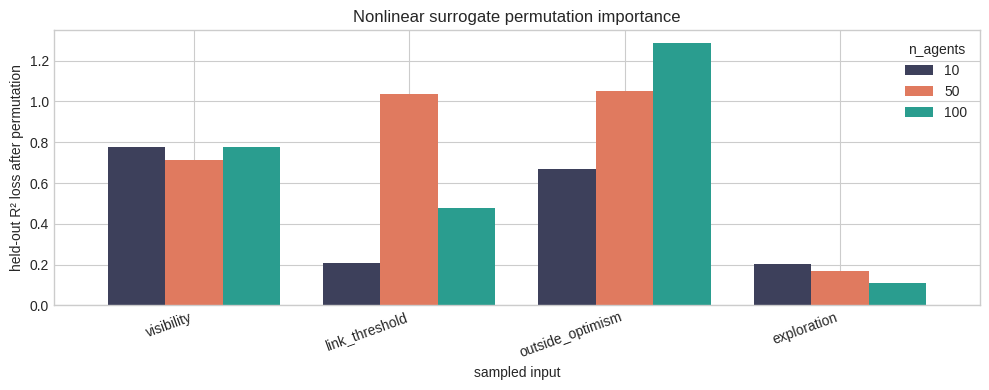

In [11]:
importance_table = pd.DataFrame(importance_rows)
importance_pivot = importance_table.pivot(
    index="feature", columns="n_agents", values="permutation_R2_loss"
).loc[feature_names]
importance_pivot.plot.bar(
    figsize=(10, 4),
    color=[SIZE_COLORS[size] for size in n_agents],
    width=0.8,
)
plt.ylabel("held-out R² loss after permutation")
plt.xlabel("sampled input")
plt.title("Nonlinear surrogate permutation importance")
plt.xticks(rotation=20, ha="right")
plt.legend(title="n_agents", frameon=False)
plt.tight_layout()
plt.show()

## 6. Network Mechanisms

Mean indegree measures link abundance. Central point of dominance measures concentration around a high-betweenness node (zero for the empty network and one for a star). Associations with welfare are mechanism-consistent descriptions, not causal mediation estimates.

In [12]:
mechanism_rows = []
mechanism_curves = {}

for output_name, label in [
    ("indegree.mean", "mean indegree"),
    ("central_point_of_dominance.mean", "central point of dominance"),
]:
    values = extract_normalized_output(output_name, normalized_time)
    delta = values[:, WITH_THRESHOLD] - values[:, WITHOUT_THRESHOLD]
    mechanism_curves[label] = delta.mean(axis=1)

    for size_index, size in enumerate(n_agents):
        terminal_delta = delta[size_index, :, -1]
        q05, median, q95 = np.quantile(terminal_delta, [0.05, 0.50, 0.95])
        mechanism_rows.append(
            {
                "n_agents": size,
                "outcome": label,
                "All-BR mean": values[size_index, WITHOUT_THRESHOLD, :, -1].mean(),
                "One-threshold mean": values[size_index, WITH_THRESHOLD, :, -1].mean(),
                "Mean change": terminal_delta.mean(),
                "Median change": median,
                "5%-95% parameter range": f"[{q05:.4f}, {q95:.4f}]",
                "Spearman rho with welfare effect": spearmanr(
                    terminal_delta, welfare_delta[size_index, :, -1]
                ).statistic,
            }
        )
    del values, delta

mechanism_summary = pd.DataFrame(mechanism_rows).set_index(
    ["n_agents", "outcome"]
)
mechanism_summary.style.format(
    {
        "All-BR mean": "{:.4f}",
        "One-threshold mean": "{:.4f}",
        "Mean change": "{:.4f}",
        "Median change": "{:.4f}",
        "Spearman rho with welfare effect": "{:.3f}",
    }
)

,,All-BR mean,One-threshold mean,Mean change,Median change,5%-95% parameter range,Spearman rho with welfare effect
n_agents,outcome,,,,,,
10,mean indegree,0.8405,0.7868,-0.0537,-0.0500,"[-0.1438, 0.0187]",0.629
50,mean indegree,1.3156,1.4143,0.0987,0.0000,"[-0.2238, 0.7086]",0.239
100,mean indegree,1.9196,2.0267,0.1071,0.0137,"[-0.2988, 0.5506]",0.144
10,central point of dominance,0.4912,0.4142,-0.0770,-0.0584,"[-0.2429, 0.0368]",0.885
50,central point of dominance,0.2215,0.5244,0.3029,0.1702,"[-0.0268, 0.8248]",0.871
100,central point of dominance,0.0774,0.4733,0.3959,0.3295,"[-0.0001, 0.9421]",0.912


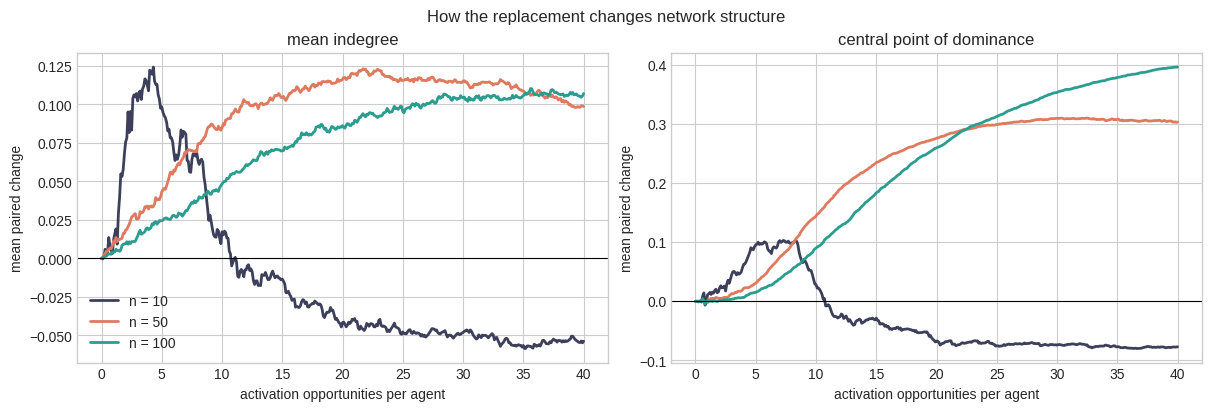

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for (label, curves), ax in zip(mechanism_curves.items(), axes, strict=True):
    for size_index, size in enumerate(n_agents):
        ax.plot(
            normalized_time,
            curves[size_index],
            color=SIZE_COLORS[size],
            lw=2,
            label=f"n = {size}",
        )
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(label)
    ax.set_xlabel("activation opportunities per agent")
    ax.set_ylabel("mean paired change")
axes[0].legend(frameon=False)
fig.suptitle("How the replacement changes network structure")
plt.show()

## 7. Distribution of Benefits and Costs

Aggregate welfare can improve even when the threshold-link agent pays for many of the links that benefit its peers. Policy-specific payoff uses a different normalization from aggregate welfare, so the two scales are reported separately.

In [14]:
policy_welfare = extract_normalized_output(
    "policy_welfare.mean", np.asarray([40.0])
)
threshold_agent_payoff = policy_welfare[:, WITH_THRESHOLD, :, 0, 0]
treated_BR_payoff = policy_welfare[:, WITH_THRESHOLD, :, 0, 1]
baseline_BR_payoff = policy_welfare[:, WITHOUT_THRESHOLD, :, 0, 1]
del policy_welfare

policy_rows = []
for size_index, size in enumerate(n_agents):
    threshold_payoff = threshold_agent_payoff[size_index]
    treated_peer_payoff = treated_BR_payoff[size_index]
    baseline_peer_payoff = baseline_BR_payoff[size_index]
    policy_rows.append(
        {
            "n_agents": size,
            "Threshold-agent mean": np.nanmean(threshold_payoff),
            "Threshold-agent median": np.nanmedian(threshold_payoff),
            "Treated-BR mean": np.nanmean(treated_peer_payoff),
            "Baseline-BR mean": np.nanmean(baseline_peer_payoff),
            "Threshold minus treated BR": np.nanmean(
                threshold_payoff - treated_peer_payoff
            ),
            "Treated BR minus baseline BR": np.nanmean(
                treated_peer_payoff - baseline_peer_payoff
            ),
            "P(threshold agent > treated BR)": np.nanmean(
                threshold_payoff > treated_peer_payoff
            ),
        }
    )

policy_summary = pd.DataFrame(policy_rows).set_index("n_agents")
policy_summary.style.format(
    {
        "Threshold-agent mean": "{:.4f}",
        "Threshold-agent median": "{:.4f}",
        "Treated-BR mean": "{:.4f}",
        "Baseline-BR mean": "{:.4f}",
        "Threshold minus treated BR": "{:.4f}",
        "Treated BR minus baseline BR": "{:.4f}",
        "P(threshold agent > treated BR)": "{:.1%}",
    }
)

,Threshold-agent mean,Threshold-agent median,Treated-BR mean,Baseline-BR mean,Threshold minus treated BR,Treated BR minus baseline BR,P(threshold agent > treated BR)
n_agents,,,,,,,
10,0.3458,0.2815,0.4046,0.4598,-0.0588,-0.0552,38.4%
50,-2.8966,-2.0143,0.3748,0.1678,-3.2714,0.2070,24.9%
100,-5.3160,-7.4650,0.1853,-0.0460,-5.5014,0.2313,13.5%


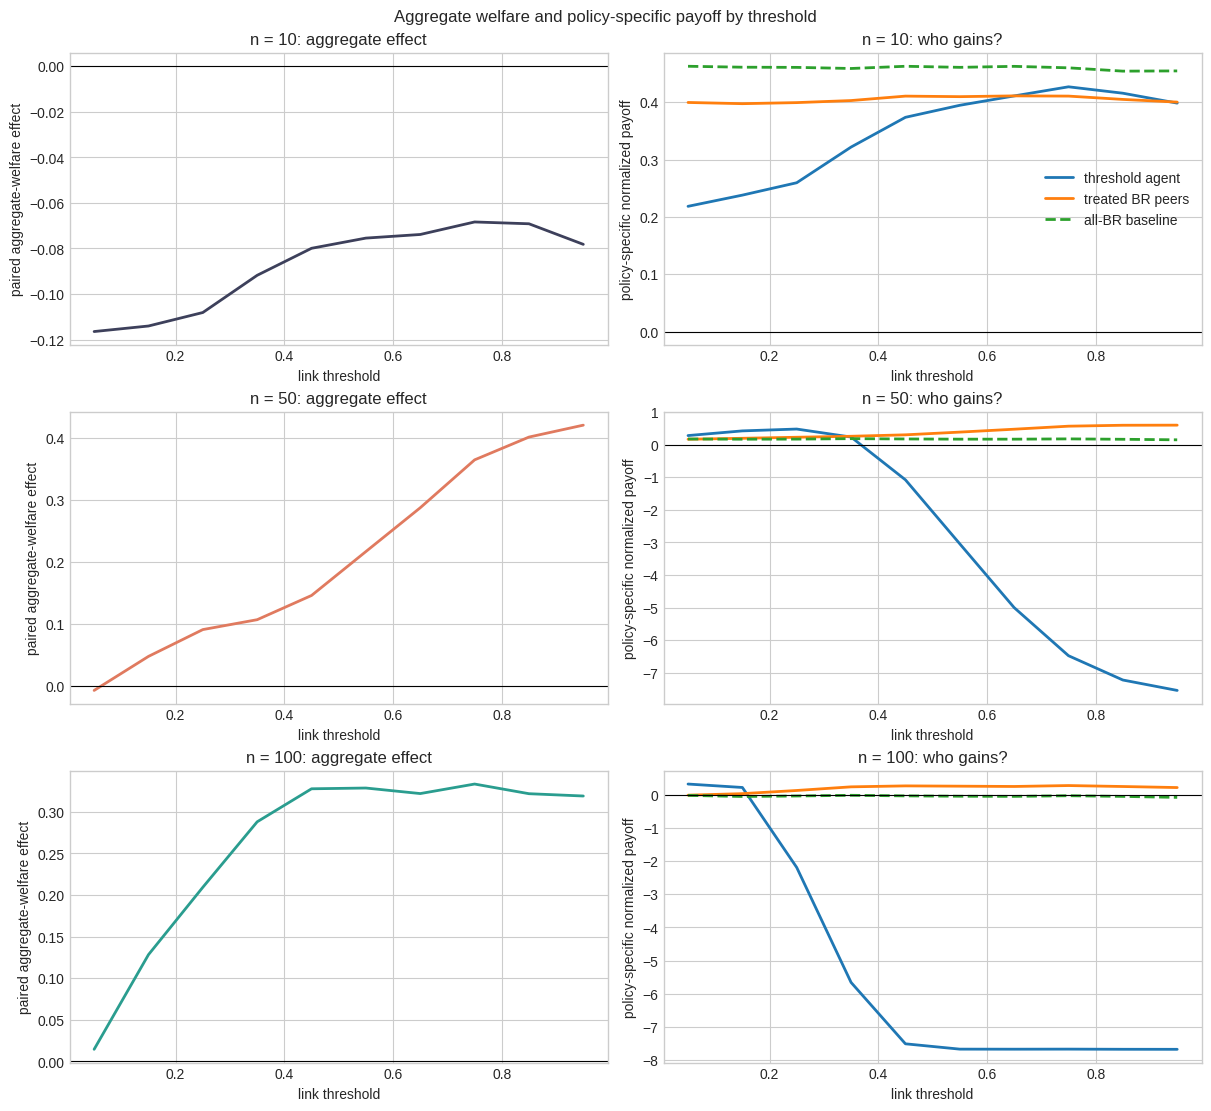

In [15]:
threshold_bin = pd.cut(
    theta.link_threshold, threshold_edges, labels=False, include_lowest=True
)
fig, axes = plt.subplots(3, 2, figsize=(12, 11), constrained_layout=True)

for size_index, size in enumerate(n_agents):
    rows = []
    for bin_index in range(10):
        selected = np.asarray(threshold_bin == bin_index)
        rows.append(
            {
                "threshold": theta.loc[selected, "link_threshold"].mean(),
                "global_effect": welfare_delta[size_index, selected, -1].mean(),
                "threshold_payoff": np.nanmean(
                    threshold_agent_payoff[size_index, selected]
                ),
                "treated_BR_payoff": np.nanmean(
                    treated_BR_payoff[size_index, selected]
                ),
                "baseline_BR_payoff": np.nanmean(
                    baseline_BR_payoff[size_index, selected]
                ),
            }
        )
    profile = pd.DataFrame(rows)

    left, right = axes[size_index]
    left.plot(profile.threshold, profile.global_effect, color=SIZE_COLORS[size], lw=2)
    left.axhline(0, color="black", lw=0.8)
    left.set_ylabel("paired aggregate-welfare effect")
    left.set_title(f"n = {size}: aggregate effect")

    right.plot(profile.threshold, profile.threshold_payoff, lw=2, label="threshold agent")
    right.plot(profile.threshold, profile.treated_BR_payoff, lw=2, label="treated BR peers")
    right.plot(profile.threshold, profile.baseline_BR_payoff, lw=2, ls="--", label="all-BR baseline")
    right.axhline(0, color="black", lw=0.8)
    right.set_ylabel("policy-specific normalized payoff")
    right.set_title(f"n = {size}: who gains?")

    left.set_xlabel("link threshold")
    right.set_xlabel("link threshold")

axes[0, 1].legend(frameon=False)
fig.suptitle("Aggregate welfare and policy-specific payoff by threshold")
plt.show()

## 8. Conclusions

- Replacing one best-response agent is harmful at the common horizon for $n=10$, but beneficial on average for $n=50$ and $n=100$.
- The $n=10$ effect is temporarily positive before reversing. The larger-network gains emerge later.
- Threshold effects are nonlinear and interact strongly with visibility and outside optimism; a single OLS slope is not an adequate summary.
- Welfare changes track changes in centralization much more closely than changes in link abundance.
- In larger networks, aggregate gains and best-response-peer gains coexist with a large negative payoff for the threshold-link agent. This private-cost/social-benefit split is central to interpreting the intervention.

## Reporting Notes

- Parameter-row ranges and proportions describe the fixed design; they are not sampling confidence intervals.
- Episode outputs were stored as 16-episode means, so episode-level simulation variance is not available.
- This is a space-filling Sobol QMC design, not the Saltelli matrix required for conventional Sobol sensitivity indices.
- The nonlinear surrogate is assessed only as a predictive description of the available effect surface.
- The artifact uses $2^{14}=16{,}384$ parameter rows and stores centralization and policy welfare; paper methods describing a $2^{12}$ benchmark run should not be reused for this analysis without revision.